
Estrechamiento (lambda) : 0.6486
Cuerda Media (MAC)      : 0.2619 m
Posición y_ca           : 0.8994 m
Posición x_ca           : 0.2694 m



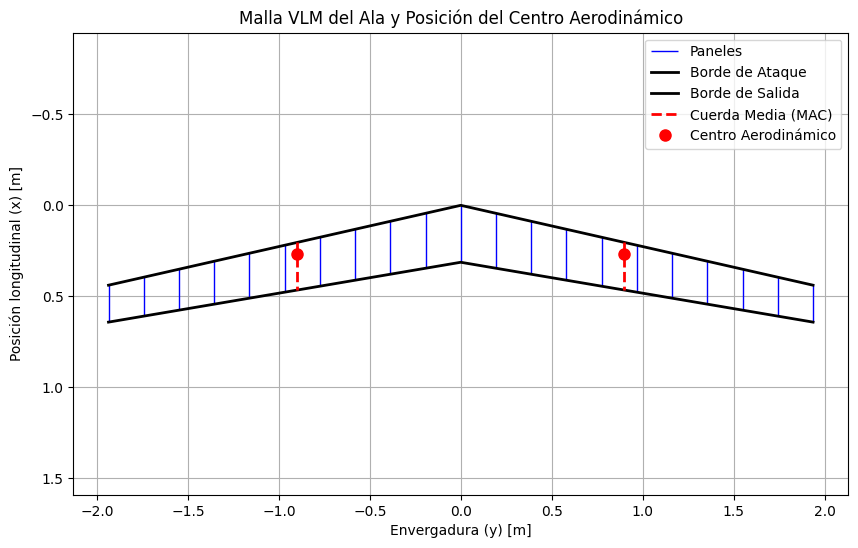

In [8]:
import numpy as np
import matplotlib.pyplot as plt

b = 3.873
c_r = 0.313
c_t = 0.203
Ny_semi = 10
Ny = 2 * Ny_semi
S = 1
Lambda_1_4_deg = 12.0

Lambda_1_4_rad = np.radians(Lambda_1_4_deg)

estrechamiento = c_t / c_r
MAC = (2/3) * c_r * ((1 + estrechamiento + estrechamiento**2) / (1 + estrechamiento))
y_ca = (b / 6) * ((1 + 2 * estrechamiento) / (1 + estrechamiento))

tan_LE = np.tan(Lambda_1_4_rad) + (0.25 * (c_r - c_t) / (b/2))
tan_TE = np.tan(Lambda_1_4_rad) - (0.75 * (c_r - c_t) / (b/2))

x_ca = y_ca * tan_LE + 0.25 * MAC

print("\n" + "="*50)
print(f"Estrechamiento (lambda) : {estrechamiento:.4f}")
print(f"Cuerda Media (MAC)      : {MAC:.4f} m")
print(f"Posición y_ca           : {y_ca:.4f} m")
print(f"Posición x_ca           : {x_ca:.4f} m")
print("="*50 + "\n")

y = np.linspace(-b/2, b/2, 2 * Ny_semi + 1)

x_BA = np.abs(y) * tan_LE
x_BS = c_r + np.abs(y) * tan_TE

plt.figure(figsize=(10, 6))

plt.vlines(x=y, ymin=x_BA, ymax=x_BS, colors='b', linewidth=1, label='Paneles')

plt.plot(y, x_BA, 'k-', linewidth=2, label='Borde de Ataque')
plt.plot(y, x_BS, 'k-', linewidth=2, label='Borde de Salida')

x_MAC_LE = y_ca * tan_LE
plt.vlines(x=[-y_ca, y_ca], ymin=x_MAC_LE, ymax=x_MAC_LE + MAC, colors='r', linestyles='dashed', linewidth=2, label='Cuerda Media (MAC)')

plt.plot([-y_ca, y_ca], [x_ca, x_ca], 'ro', markersize=8, label='Centro Aerodinámico')

plt.gca().invert_yaxis()
plt.axis('equal')
plt.title("Malla VLM del Ala y Posición del Centro Aerodinámico")
plt.xlabel("Envergadura (y) [m]")
plt.ylabel("Posición longitudinal (x) [m]")

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.grid(True)
plt.show()

Panel    | y [m]      | Cl(-12º) | Cl( -6º) | Cl(  0º) | Cl(  6º) | Cl( 12º)
-------------------------------------------------------------------------------------
1        | -1.840     |   -0.997 |   -0.546 |   -0.094 |    0.358 |    0.810
2        | -1.646     |   -1.161 |   -0.619 |   -0.077 |    0.465 |    1.007
3        | -1.452     |   -1.186 |   -0.614 |   -0.041 |    0.531 |    1.103
4        | -1.259     |   -1.169 |   -0.585 |   -0.001 |    0.583 |    1.167
5        | -1.065     |   -1.135 |   -0.547 |    0.040 |    0.628 |    1.216
6        | -0.871     |   -1.092 |   -0.505 |    0.081 |    0.667 |    1.254
7        | -0.678     |   -1.044 |   -0.462 |    0.119 |    0.701 |    1.283
8        | -0.484     |   -0.993 |   -0.420 |    0.154 |    0.727 |    1.300
9        | -0.290     |   -0.939 |   -0.379 |    0.181 |    0.741 |    1.302
10       | -0.097     |   -0.881 |   -0.342 |    0.198 |    0.737 |    1.277
11       | 0.097      |   -0.881 |   -0.342 |    0.198 |    0.737 |

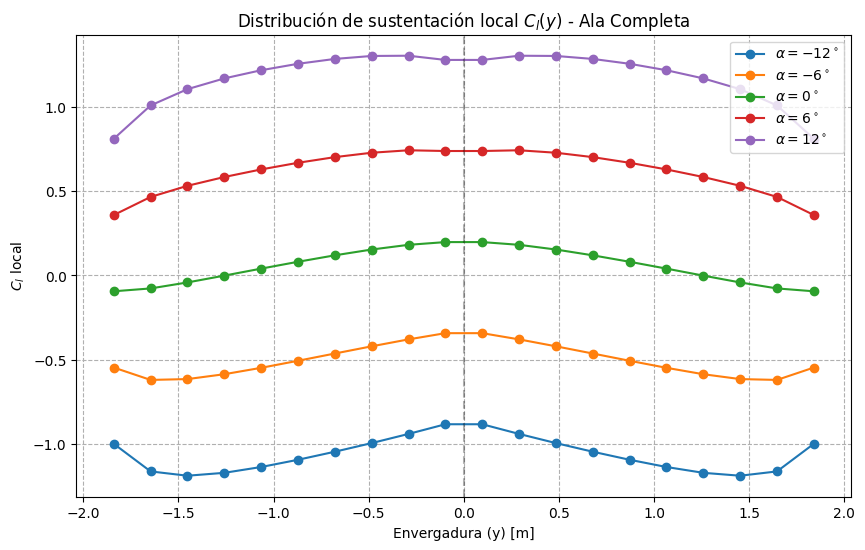

In [9]:
y_panels = np.linspace(-b/2, b/2, Ny + 1)
y_m = (y_panels[:-1] + y_panels[1:]) / 2.0

c_m = c_r - (c_r - c_t) * np.abs(y_m) / (b/2)
c_nodos = c_r - (c_r - c_t) * np.abs(y_panels) / (b/2)
x_14_nodos = np.abs(y_panels) * tan_LE + 0.25 * c_nodos
x_control = np.abs(y_m) * tan_LE + 0.75 * c_m

torsion_local = np.radians(-5.0 * np.abs(y_m) / (b/2))
dyc_dx_34 = (2 * 0.03 / (1 - 0.20)**2) * (0.20 - 0.75)

def calc_a_ij(xc, yc, x1, y1, x2, y2):
    a, b_dist = xc - x1, yc - y1
    c, d_dist = xc - x2, yc - y2
    e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c**2 + d_dist**2)
    g, h = x2 - x1, y2 - y1

    den_k = a*d_dist - c*b_dist
    k = (g*a + h*b_dist)/e - (g*c + h*d_dist)/f
    k = k / den_k if abs(den_k) > 1e-9 else 0

    l = 0
    if abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9:
        l = -(1/b_dist)*(1 + a/e) + (1/d_dist)*(1 + c/f)

    return (1/(4*np.pi)) * (k + l)

A_mat = np.zeros((Ny, Ny))
for i in range(Ny):
    for j in range(Ny):
        A_mat[i, j] = calc_a_ij(x_control[i], y_m[i],
                                x_14_nodos[j], y_panels[j],
                                x_14_nodos[j+1], y_panels[j+1])

alphas_deg = np.array([-12, -6, 0, 6, 12])
alphas_rad = np.radians(alphas_deg)

B_mat = -(alphas_rad[np.newaxis, :] + torsion_local[:, np.newaxis] - dyc_dx_34)

Gamma_Uinf_matrix = np.linalg.solve(A_mat, B_mat)


cl_resultados = 2 * Gamma_Uinf_matrix / c_m[:, np.newaxis]

header = f"{'Panel':<8} | {'y [m]':<10} | " + " | ".join([f"Cl({a:>3}º)" for a in alphas_deg])
print(header)
print("-" * 85)

for i in range(Ny):
    valores_cl = " | ".join([f"{cl_resultados[i, j]:>8.3f}" for j in range(len(alphas_deg))])
    print(f"{i + 1:<8} | {y_m[i]:<10.3f} | {valores_cl}")
print("="*85)

plt.figure(figsize=(10, 6))
for idx, a_deg in enumerate(alphas_deg):
    plt.plot(y_m, cl_resultados[:, idx], '-o', label=f'$\\alpha = {a_deg}^\\circ$')

plt.title("Distribución de sustentación local $C_l(y)$ - Ala Completa")
plt.xlabel("Envergadura (y) [m]")
plt.ylabel("$C_l$ local")
plt.xlim(-b/2 - 0.1, b/2 + 0.1)
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.grid(True, linestyle='--')
plt.legend()
plt.show()


         APARTADO 4: PARÁMETROS GLOBALES DE SUSTENTACIÓN         
Parámetro                           | Valor      | Unidades
-----------------------------------------------------------------
Pendiente sustentación (CL_alpha)   | 5.342      | 1/rad
Pendiente sustentación (CL_alpha)   | 0.0932     | 1/deg
CL a cero grados (CL_a=0)           | 0.068      | Adimensional
Ángulo sustentación nula (a_L=0)    | -0.73      | grados


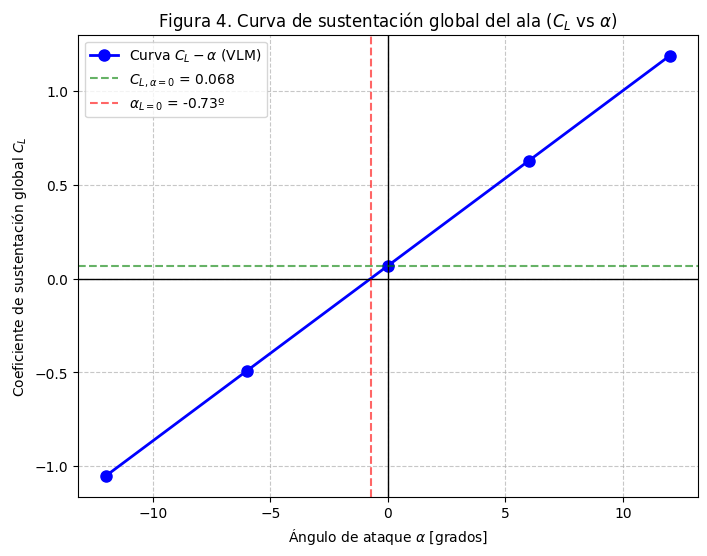

In [10]:
dy = b / Ny
CL_global = np.sum(cl_resultados * c_m[:, np.newaxis] * dy, axis=0) / S

coeficientes = np.polyfit(alphas_deg, CL_global, 1)
CL_alpha_deg = coeficientes[0]
CL_alpha_0 = coeficientes[1]


CL_alpha_rad = CL_alpha_deg * np.degrees(1)
alpha_L0_deg = -CL_alpha_0 / CL_alpha_deg

print("\n" + "="*65)
print(f"{'APARTADO 4: PARÁMETROS GLOBALES DE SUSTENTACIÓN':^65}")
print("="*65)
print(f"{'Parámetro':<35} | {'Valor':<10} | {'Unidades'}")
print("-" * 65)
print(f"{'Pendiente sustentación (CL_alpha)':<35} | {CL_alpha_rad:<10.3f} | 1/rad")
print(f"{'Pendiente sustentación (CL_alpha)':<35} | {CL_alpha_deg:<10.4f} | 1/deg")
print(f"{'CL a cero grados (CL_a=0)':<35} | {CL_alpha_0:<10.3f} | Adimensional")
print(f"{'Ángulo sustentación nula (a_L=0)':<35} | {alpha_L0_deg:<10.2f} | grados")
print("="*65)

plt.figure(figsize=(8, 6))
plt.plot(alphas_deg, CL_global, 'b-o', linewidth=2, markersize=8, label='Curva $C_L - \\alpha$ (VLM)')

plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.axhline(CL_alpha_0, color='green', linestyle='--', alpha=0.6, label=f'$C_{{L, \\alpha=0}}$ = {CL_alpha_0:.3f}')
plt.axvline(alpha_L0_deg, color='red', linestyle='--', alpha=0.6, label=f'$\\alpha_{{L=0}}$ = {alpha_L0_deg:.2f}º')

plt.title("Figura 4. Curva de sustentación global del ala ($C_L$ vs $\\alpha$)")
plt.xlabel("Ángulo de ataque $\\alpha$ [grados]")
plt.ylabel("Coeficiente de sustentación global $C_L$")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


     APARTADO 5: DISTRIBUCIONES BÁSICA Y ADICIONAL (Ala Derecha)      
Panel    | y [m]      | Cl_b (Básica)   | Cl_a (Adicional)
----------------------------------------------------------------------
1        | 0.097      | 0.132           | 0.964          
2        | 0.290      | 0.113           | 1.001          
3        | 0.484      | 0.084           | 1.025          
4        | 0.678      | 0.048           | 1.040          
5        | 0.871      | 0.009           | 1.048          
6        | 1.065      | -0.031          | 1.050          
7        | 1.259      | -0.072          | 1.044          
8        | 1.452      | -0.111          | 1.023          
9        | 1.646      | -0.143          | 0.969          
10       | 1.840      | -0.149          | 0.807          


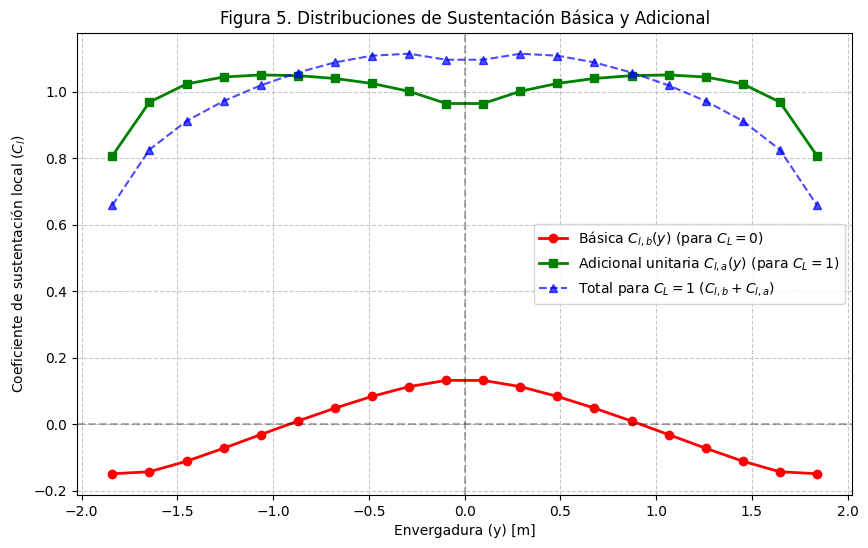

In [11]:
alpha_L0_rad = np.radians(alpha_L0_deg)
RHS_b = -(alpha_L0_rad + torsion_local - dyc_dx_34)
gamma_b = np.linalg.solve(A_mat, RHS_b)
Cl_b = 2 * gamma_b / c_m

RHS_a_temp = -np.ones(Ny)
gamma_a_temp = np.linalg.solve(A_mat, RHS_a_temp)
Cl_a_temp = 2 * gamma_a_temp / c_m

CL_a_global_temp = np.sum(Cl_a_temp * c_m * dy) / S
Cl_a = Cl_a_temp / CL_a_global_temp

print("\n" + "="*70)
print(f"{'APARTADO 5: DISTRIBUCIONES BÁSICA Y ADICIONAL (Ala Derecha)':^70}")
print("="*70)
print(f"{'Panel':<8} | {'y [m]':<10} | {'Cl_b (Básica)':<15} | {'Cl_a (Adicional)':<15}")
print("-" * 70)

indices_derecha = np.where(y_m >= 0)[0]

for n, i in enumerate(indices_derecha):
    print(f"{n+1:<8} | {y_m[i]:<10.3f} | {Cl_b[i]:<15.3f} | {Cl_a[i]:<15.3f}")
print("="*70)

plt.figure(figsize=(10, 6))

plt.plot(y_m, Cl_b, 'r-o', linewidth=2, label='Básica $C_{l,b}(y)$ (para $C_L=0$)')
plt.plot(y_m, Cl_a, 'g-s', linewidth=2, label='Adicional unitaria $C_{l,a}(y)$ (para $C_L=1$)')

Cl_total_CL1 = Cl_b + Cl_a * 1.0
plt.plot(y_m, Cl_total_CL1, 'b--^', alpha=0.7, label='Total para $C_L=1$ ($C_{l,b} + C_{l,a}$)')

plt.title("Figura 5. Distribuciones de Sustentación Básica y Adicional")
plt.xlabel("Envergadura (y) [m]")
plt.ylabel("Coeficiente de sustentación local ($C_l$)")
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.axhline(0, color='black', linestyle='--', alpha=0.3)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


     APARTADO 6: COEFICIENTE DE RESISTENCIA INDUCIDA LOCAL cdi(y) (Ala Derecha)      
Panel    | y [m]      | cdi(-12º) | cdi( -6º) | cdi(  0º) | cdi(  6º) | cdi( 12º)
-------------------------------------------------------------------------------------
1        | 0.097      |   0.0061 |  -0.0006 |   0.0021 |   0.0143 |   0.0360
2        | 0.290      |   0.0114 |   0.0008 |   0.0014 |   0.0132 |   0.0362
3        | 0.484      |   0.0144 |   0.0020 |   0.0008 |   0.0108 |   0.0321
4        | 0.678      |   0.0170 |   0.0031 |   0.0003 |   0.0087 |   0.0281
5        | 0.871      |   0.0199 |   0.0044 |   0.0001 |   0.0069 |   0.0249
6        | 1.065      |   0.0235 |   0.0060 |  -0.0000 |   0.0055 |   0.0226
7        | 1.259      |   0.0286 |   0.0080 |   0.0000 |   0.0046 |   0.0218
8        | 1.452      |   0.0363 |   0.0109 |   0.0002 |   0.0041 |   0.0227
9        | 1.646      |   0.0487 |   0.0154 |   0.0006 |   0.0044 |   0.0266
10       | 1.840      |   0.0657 |   0.0213 |   0.00

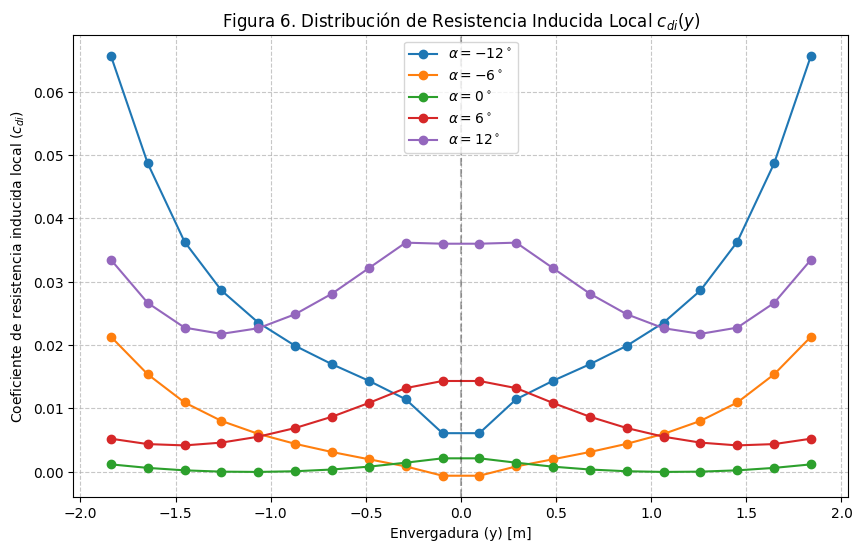

In [12]:
termino_izq = 1.0 / (y_m[:, np.newaxis] - y_panels[:-1])
termino_der = 1.0 / (y_m[:, np.newaxis] - y_panels[1:])
A_Trefftz = (1.0 / (2 * np.pi)) * (termino_izq - termino_der)

gamma_v_matrix = cl_resultados * (c_m[:, np.newaxis] / 2.0)

w_Trefftz_matrix = A_Trefftz @ gamma_v_matrix
alpha_i_matrix = w_Trefftz_matrix / 2.0
cdi_resultados = cl_resultados * alpha_i_matrix
CDi_global = np.sum(cdi_resultados * c_m[:, np.newaxis] * dy, axis=0) / S

print("\n" + "="*85)
print(f"{'APARTADO 6: COEFICIENTE DE RESISTENCIA INDUCIDA LOCAL cdi(y) (Ala Derecha)':^85}")
print("="*85)
header_cdi = f"{'Panel':<8} | {'y [m]':<10} | " + " | ".join([f"cdi({a:>3}º)" for a in alphas_deg])
print(header_cdi)
print("-" * 85)

indices_derecha = np.where(y_m >= 0)[0]
for n, i in enumerate(indices_derecha):

    valores_cdi = " | ".join([f"{cdi_resultados[i, j]:>8.4f}" for j in range(len(alphas_deg))])
    print(f"{n+1:<8} | {y_m[i]:<10.3f} | {valores_cdi}")
print("="*85)

print("\n" + "="*50)
print(f"{'CDi GLOBAL DEL ALA':^50}")
print("="*50)
print(f"{'Ángulo de ataque':<20} | {'CDi Global'}")
print("-" * 50)
for idx, a_deg in enumerate(alphas_deg):

    print(f"{a_deg:>10} º          | {CDi_global[idx]:.4f}")
print("="*50)

plt.figure(figsize=(10, 6))
for idx, a_deg in enumerate(alphas_deg):
    plt.plot(y_m, cdi_resultados[:, idx], '-o', label=f'$\\alpha = {a_deg}^\\circ$')

plt.title("Figura 6. Distribución de Resistencia Inducida Local $c_{di}(y)$")
plt.xlabel("Envergadura (y) [m]")
plt.ylabel("Coeficiente de resistencia inducida local ($c_{di}$)")
plt.xlim(-b/2 - 0.1, b/2 + 0.1)
plt.axvline(0, color='black', linestyle='--', alpha=0.3)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


         APARTADO 7: COEFICIENTES DE MOMENTO DE CABECEO          
Ángulo (º)      | CM_0y (Eje OY)       | CM_caw (Centro Aero)
-----------------------------------------------------------------
       -12 º    |           1.115      |           0.034
        -6 º    |           0.545      |           0.040
         0 º    |          -0.026      |           0.045
         6 º    |          -0.596      |           0.050
        12 º    |          -1.166      |           0.055


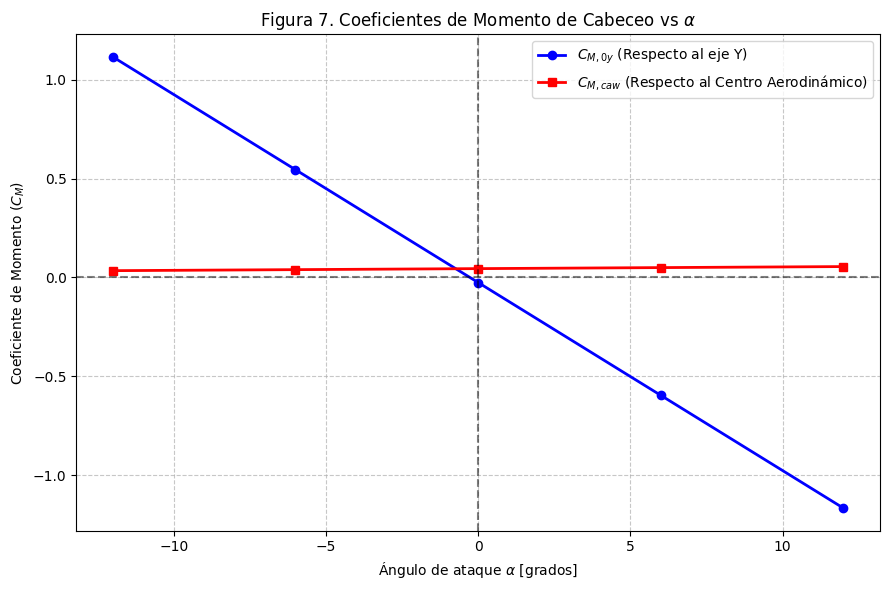

In [13]:
x_14_m = np.abs(y_m) * tan_LE + 0.25 * c_m


CM_0y_global = np.sum(-cl_resultados * (c_m * x_14_m)[:, np.newaxis] * dy, axis=0) / (S * MAC)

CM_ca_global = CM_0y_global + CL_global * (x_ca / MAC)

print("\n" + "="*65)
print(f"{'APARTADO 7: COEFICIENTES DE MOMENTO DE CABECEO':^65}")
print("="*65)
print(f"{'Ángulo (º)':<15} | {'CM_0y (Eje OY)':<20} | {'CM_caw (Centro Aero)'}")
print("-" * 65)

for idx, a_deg in enumerate(alphas_deg):
    print(f"{a_deg:>10} º    | {CM_0y_global[idx]:>15.3f}      | {CM_ca_global[idx]:>15.3f}")
print("="*65)

plt.figure(figsize=(9, 6))

plt.plot(alphas_deg, CM_0y_global, 'b-o', linewidth=2, label='$C_{M, 0y}$ (Respecto al eje Y)')
plt.plot(alphas_deg, CM_ca_global, 'r-s', linewidth=2, label='$C_{M, caw}$ (Respecto al Centro Aerodinámico)')

plt.title("Figura 7. Coeficientes de Momento de Cabeceo vs $\\alpha$")
plt.xlabel("Ángulo de ataque $\\alpha$ [grados]")
plt.ylabel("Coeficiente de Momento ($C_M$)")
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.axvline(0, color='black', linestyle='--', alpha=0.5)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Mounted at /content/drive
[ERROR] Hubo un problema leyendo el archivo: /content/drive/MyDrive/Trabajo Alas/xflr 5 Cl.txt not found.


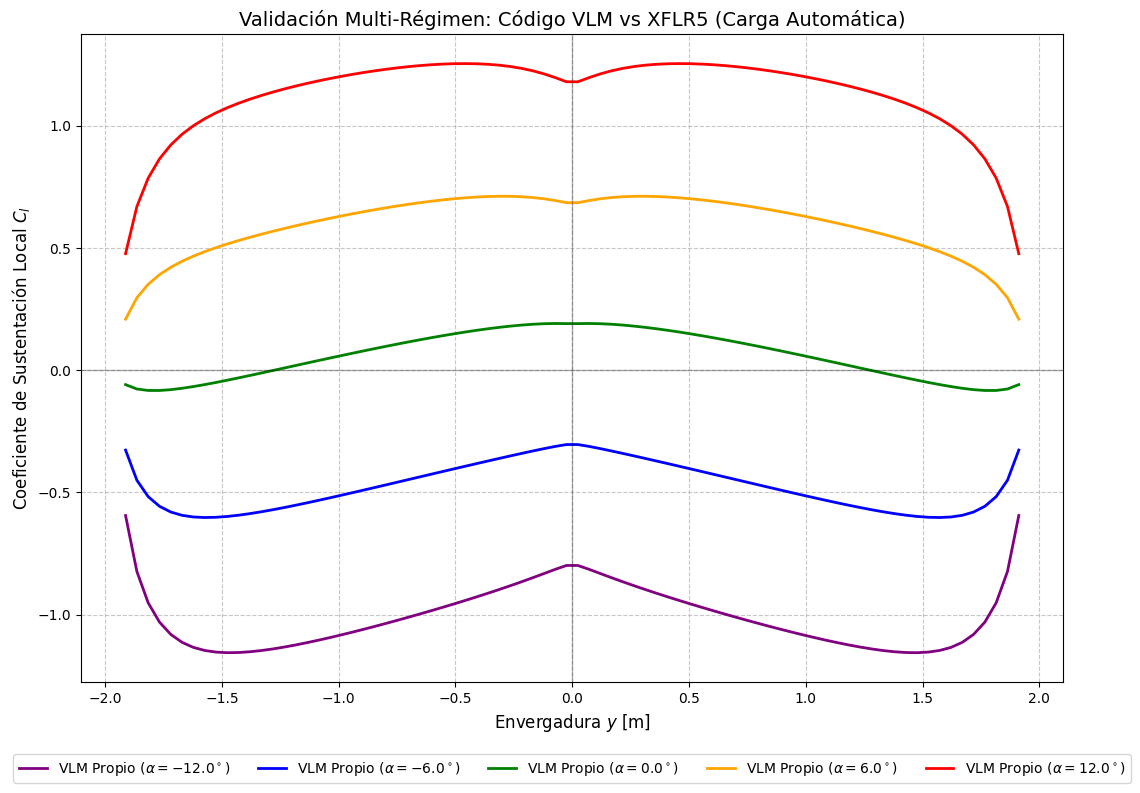

In [14]:
import os
from google.colab import drive

drive.mount('/content/drive')
ruta_archivo = '/content/drive/MyDrive/Trabajo Alas/xflr 5 Cl.txt'

b = 3.873
c_r = 0.313
c_t = 0.203
torsion_punta = -5.0
flecha_BA = 20.0
tan_LE = np.tan(np.radians(flecha_BA))
alphas_validar = [-12.0, -6.0, 0.0, 6.0, 12.0]

try:
    datos_xflr5 = np.loadtxt(ruta_archivo, skiprows=1)

    xflr5_y = datos_xflr5[:, 0]


    xflr5_cl = {
        -12.0: datos_xflr5[:, 1],
         -6.0: datos_xflr5[:, 3],
          0.0: datos_xflr5[:, 5],
          6.0: datos_xflr5[:, 7],
         12.0: datos_xflr5[:, 9]
    }
    print("[OK] Datos de XFLR5 parseados con éxito.\n")
except Exception as e:
    print(f"[ERROR] Hubo un problema leyendo el archivo: {e}")


def resolver_vlm(Ny, alpha_deg):
    alpha_rad = np.radians(alpha_deg)
    y_panels = np.linspace(-b/2, b/2, Ny + 1)
    y_m = (y_panels[:-1] + y_panels[1:]) / 2.0

    c_m = c_r - (c_r - c_t) * np.abs(y_m) / (b/2)
    c_nodos = c_r - (c_r - c_t) * np.abs(y_panels) / (b/2)
    x_14_nodos = np.abs(y_panels) * tan_LE + 0.25 * c_nodos
    x_control = np.abs(y_m) * tan_LE + 0.75 * c_m
    torsion_local = np.radians(torsion_punta * np.abs(y_m) / (b/2))
    dyc_dx_34 = (2 * 0.03 / (1 - 0.20)**2) * (0.20 - 0.75)

    A_mat = np.zeros((Ny, Ny))
    for i in range(Ny):
        for j in range(Ny):
            a, b_dist = x_control[i] - x_14_nodos[j], y_m[i] - y_panels[j]
            c_dist, d_dist = x_control[i] - x_14_nodos[j+1], y_m[i] - y_panels[j+1]
            e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c_dist**2 + d_dist**2)
            g, h = x_14_nodos[j+1] - x_14_nodos[j], y_panels[j+1] - y_panels[j]

            den_k = a*d_dist - c_dist*b_dist
            k = ((g*a + h*b_dist)/e - (g*c_dist + h*d_dist)/f) / den_k if abs(den_k) > 1e-9 else 0
            l = -(1/b_dist)*(1 + a/e) + (1/d_dist)*(1 + c_dist/f) if (abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9) else 0
            A_mat[i, j] = (1/(4*np.pi)) * (k + l)

    RHS = -(alpha_rad + torsion_local - dyc_dx_34)
    gamma_v = np.linalg.solve(A_mat, RHS)
    return y_m, 2 * gamma_v / c_m


plt.figure(figsize=(12, 8))
colores = {-12.0: 'purple', -6.0: 'blue', 0.0: 'green', 6.0: 'orange', 12.0: 'red'}

for a_deg in alphas_validar:

    y_vlm, cl_vlm = resolver_vlm(80, a_deg)


    plt.plot(y_vlm, cl_vlm, color=colores[a_deg], linestyle='-', linewidth=2,
              label=f'VLM Propio ($\\alpha={a_deg}^\\circ$)')


    if 'xflr5_cl' in locals():
        plt.plot(xflr5_y, xflr5_cl[a_deg], color=colores[a_deg], marker='o',
                  linestyle='', markersize=5, label=f'XFLR5 ($\\alpha={a_deg}^\\circ$)')

plt.title('Validación Multi-Régimen: Código VLM vs XFLR5 (Carga Automática)', fontsize=14)
plt.xlabel('Envergadura $y$ [m]', fontsize=12)
plt.ylabel('Coeficiente de Sustentación Local $C_l$', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='black', linewidth=1, alpha=0.3)
plt.axvline(0, color='black', linewidth=1, alpha=0.3)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5)
plt.tight_layout()
plt.show()


      ANÁLISIS DE SENSIBILIDAD: N_y vs TIEMPO vs CL GLOBAL       
Nº Paneles (Ny) | Tiempo (segundos)    | CL Global      
-----------------------------------------------------------------
10              | 0.0013               | 0.61812
20              | 0.0042               | 0.61249
40              | 0.0167               | 0.60778
80              | 0.0625               | 0.60521
160             | 0.2603               | 0.60393
320             | 1.9144               | 0.60329


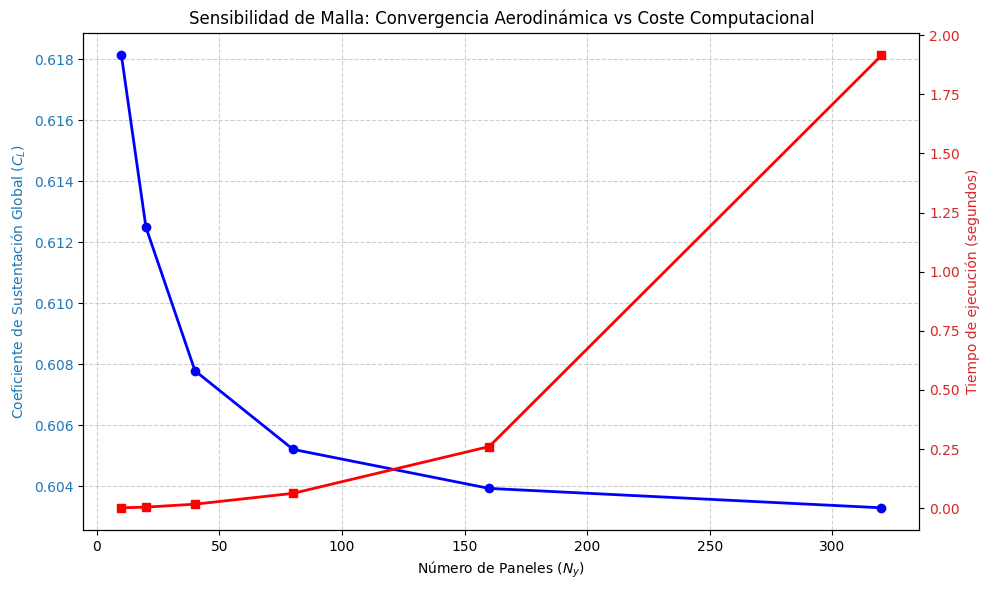

In [15]:
import time

b = 3.873
c_r = 0.313
c_t = 0.203
torsion_punta = -5.0
flecha_BA = 20.0
tan_LE = np.tan(np.radians(flecha_BA))
alpha_rad = np.radians(6.0)

paneles_test = [10, 20, 40, 80, 160, 320]

tiempos_ejecucion = []
CL_globales = []

print("\n" + "="*65)
print(f"{'ANÁLISIS DE SENSIBILIDAD: N_y vs TIEMPO vs CL GLOBAL':^65}")
print("="*65)
print(f"{'Nº Paneles (Ny)':<15} | {'Tiempo (segundos)':<20} | {'CL Global':<15}")
print("-" * 65)

for Ny in paneles_test:
    t_inicio = time.time()

    # --- VLM ---
    y_panels = np.linspace(-b/2, b/2, Ny + 1)
    y_m = (y_panels[:-1] + y_panels[1:]) / 2.0

    c_m = c_r - (c_r - c_t) * np.abs(y_m) / (b/2)
    c_nodos = c_r - (c_r - c_t) * np.abs(y_panels) / (b/2)
    x_14_nodos = np.abs(y_panels) * tan_LE + 0.25 * c_nodos
    x_control = np.abs(y_m) * tan_LE + 0.75 * c_m
    torsion_local = np.radians(torsion_punta * np.abs(y_m) / (b/2))
    dyc_dx_34 = (2 * 0.03 / (1 - 0.20)**2) * (0.20 - 0.75)

    A_mat = np.zeros((Ny, Ny))
    for i in range(Ny):
        for j in range(Ny):
            a, b_dist = x_control[i] - x_14_nodos[j], y_m[i] - y_panels[j]
            c_dist, d_dist = x_control[i] - x_14_nodos[j+1], y_m[i] - y_panels[j+1]
            e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c_dist**2 + d_dist**2)
            g, h = x_14_nodos[j+1] - x_14_nodos[j], y_panels[j+1] - y_panels[j]

            den_k = a*d_dist - c_dist*b_dist
            k = ((g*a + h*b_dist)/e - (g*c_dist + h*d_dist)/f) / den_k if abs(den_k) > 1e-9 else 0
            l = -(1/b_dist)*(1 + a/e) + (1/d_dist)*(1 + c_dist/f) if (abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9) else 0
            A_mat[i, j] = (1/(4*np.pi)) * (k + l)

    RHS = -(alpha_rad + torsion_local - dyc_dx_34)
    gamma_v = np.linalg.solve(A_mat, RHS)
    Cl_local = 2 * gamma_v / c_m

    dy_array = np.diff(y_panels)
    CL_global = np.sum(Cl_local * c_m * dy_array) / 1.0

    t_fin = time.time()
    tiempo_total = t_fin - t_inicio

    tiempos_ejecucion.append(tiempo_total)
    CL_globales.append(CL_global)

    print(f"{Ny:<15} | {tiempo_total:<20.4f} | {CL_global:.5f}")


fig, ax1 = plt.subplots(figsize=(10, 6))

color1 = 'tab:blue'
ax1.set_xlabel('Número de Paneles ($N_y$)')
ax1.set_ylabel('Coeficiente de Sustentación Global ($C_L$)', color=color1)
ax1.plot(paneles_test, CL_globales, 'b-o', linewidth=2, label='Convergencia $C_L$')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.set_ylabel('Tiempo de ejecución (segundos)', color=color2)
ax2.plot(paneles_test, tiempos_ejecucion, 'r-s', linewidth=2, label='Coste Computacional')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Sensibilidad de Malla: Convergencia Aerodinámica vs Coste Computacional')
fig.tight_layout()
plt.show()

Simulación de espacio 5D completada en 46.75 segundos.

Se han encontrado 1490 configuraciones legales. TOP 5:

Rank  | NACA   | AR      | Flecha (º)  | Estrech.   | Torsión (º)  | Est. Stall  | Gradiente  | Coste 
------------------------------------------------------------------------------------------------------
Op 1  | 4417   |    7.24 |     14.74   |     0.905  |       -9.00  |      15.0%  |     -0.201 |  1.064
Op 2  | 3217   |    6.21 |     16.84   |     0.905  |       -9.00  |      15.0%  |     -0.201 |  1.078
Op 3  | 4417   |    6.72 |     14.74   |     0.905  |       -9.00  |      15.0%  |     -0.206 |  1.081
Op 4  | 2412   |    6.21 |     12.63   |     0.811  |       -9.00  |      15.0%  |     -0.200 |  1.086
Op 5  | 4417   |    6.72 |     12.63   |     0.858  |       -9.00  |      15.0%  |     -0.202 |  1.088


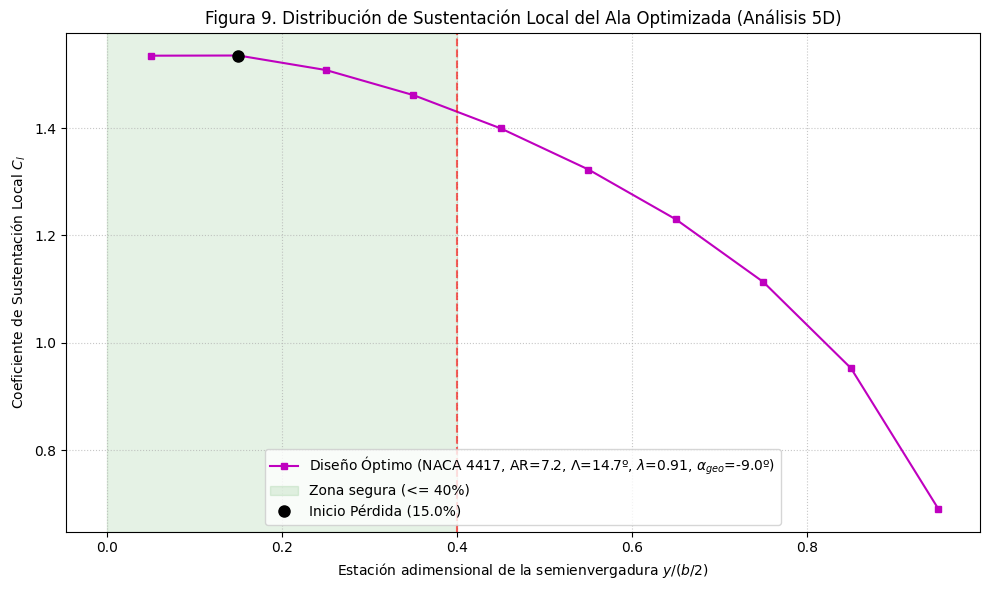

In [16]:
S = 1.0
b_orig = 3.873
AR_orig = b_orig**2 / S
c_r = 0.313
estr_orig = 0.65
torsion_orig = -5.0
flecha_orig = 20.0
Ny = 20
alpha_stall = 15.0

b_test = np.linspace(3.873, 2.0, 20)
flechas_test = np.linspace(20.0, 0.0, 20)
estrech_test = np.linspace(0.1, 1.0, 20)
torsiones_test = np.linspace(0.0, -9.0, 5)
nacas_test = ['0012', '2412', '3217', '4417']

soluciones_validas = []
t0 = time.time()

for b_curr in b_test:
    AR_curr = b_curr**2 / S
    y_panels = np.linspace(-b_curr/2, b_curr/2, Ny + 1)
    y_m = (y_panels[:-1] + y_panels[1:]) / 2.0
    indices_derecha = np.where(y_m >= 0)[0]
    y_der = y_m[indices_derecha]
    dy_val = b_curr / Ny

    for flecha in flechas_test:
        tan_LE = np.tan(np.radians(flecha))

        for estr in estrech_test:
            c_t = c_r * estr
            c_m = c_r - (c_r - c_t) * np.abs(y_m) / (b_curr/2)
            c_nodos = c_r - (c_r - c_t) * np.abs(y_panels) / (b_curr/2)
            x_14_nodos = np.abs(y_panels) * tan_LE + 0.25 * c_nodos
            x_control = np.abs(y_m) * tan_LE + 0.75 * c_m

            # Matriz A independiente de la torsión y el NACA
            A_mat = np.zeros((Ny, Ny))
            for i in range(Ny):
                for j in range(Ny):
                    a, b_dist = x_control[i] - x_14_nodos[j], y_m[i] - y_panels[j]
                    c_dist, d_dist = x_control[i] - x_14_nodos[j+1], y_m[i] - y_panels[j+1]
                    e, f = np.sqrt(a**2 + b_dist**2), np.sqrt(c_dist**2 + d_dist**2)
                    g, h = x_14_nodos[j+1] - x_14_nodos[j], y_panels[j+1] - y_panels[j]

                    den_k = a*d_dist - c_dist*b_dist
                    k = ((g*a + h*b_dist)/e - (g*c_dist + h*d_dist)/f) / den_k if abs(den_k) > 1e-9 else 0
                    l = -(1/b_dist)*(1 + a/e) + (1/d_dist)*(1 + c_dist/f) if (abs(b_dist) > 1e-9 and abs(d_dist) > 1e-9) else 0
                    A_mat[i, j] = (1/(4*np.pi)) * (k + l)

            for torsion in torsiones_test:
                torsion_local = np.radians(torsion * np.abs(y_m) / (b_curr/2))

                for naca in nacas_test:
                    # Extracción de parámetros geométricos del NACA 4 dígitos
                    m_camber = int(naca[0]) / 100.0
                    p_pos = int(naca[1]) / 10.0

                    # Cálculo de la pendiente geométrica en x/c = 0.75
                    if m_camber == 0:
                        dyc_dx_34 = 0.0 # Perfil simétrico
                    else:
                        # Asumiendo que p_pos < 0.75 para perfiles estándar
                        dyc_dx_34 = (2 * m_camber / (1 - p_pos)**2) * (p_pos - 0.75)

                    RHS = -(np.radians(alpha_stall) + torsion_local - dyc_dx_34)
                    gamma_v = np.linalg.solve(A_mat, RHS)
                    Cl_local = 2 * gamma_v / c_m

                    Cl_der = Cl_local[indices_derecha]
                    idx_stall = np.argmax(Cl_der)
                    pos_relativa = y_der[idx_stall] / (b_curr/2)
                    gradiente = (Cl_der[idx_stall + 1] - Cl_der[idx_stall]) / dy_val if idx_stall < len(Cl_der)-1 else 0

                    if pos_relativa <= 0.40 and gradiente <= -0.20:
                        penal_flecha = ((flecha - flecha_orig) / flecha_orig) ** 2 if flecha_orig != 0 else (flecha/10)**2
                        penal_estr = ((estr - estr_orig) / estr_orig) ** 2
                        penal_tors = ((torsion - torsion_orig) / torsion_orig) ** 2 if torsion_orig != 0 else (torsion/10)**2
                        penal_ar = ((AR_curr - AR_orig) / AR_orig) ** 2

                        # No penalizamos el NACA, dejamos que el coste decida puramente por planta/torsión
                        coste_total = np.sqrt(penal_flecha + penal_estr + penal_tors + penal_ar)

                        soluciones_validas.append({
                            'naca': naca, 'b': b_curr, 'AR': AR_curr, 'flecha': flecha,
                            'estr': estr, 'torsion': torsion, 'coste': coste_total,
                            'pos_relativa': pos_relativa, 'gradiente': gradiente,
                            'y_opt': y_der, 'Cl_opt': Cl_der, 'idx_stall': idx_stall
                        })

t1 = time.time()
print(f"Simulación de espacio 5D completada en {t1-t0:.2f} segundos.")

if len(soluciones_validas) > 0:
    soluciones_ordenadas = sorted(soluciones_validas, key=lambda x: x['coste'])
    top_5 = soluciones_ordenadas[:5]

    print(f"\nSe han encontrado {len(soluciones_validas)} configuraciones legales. TOP 5:\n")
    header = f"{'Rank':<5} | {'NACA':<6} | {'AR':<7} | {'Flecha (º)':<11} | {'Estrech.':<10} | {'Torsión (º)':<12} | {'Est. Stall':<11} | {'Gradiente':<10} | {'Coste':<6}"
    print(header)
    print("-" * len(header))

    for i, sol in enumerate(top_5):
        print(f"Op {i+1:<2} | {sol['naca']:<6} | {sol['AR']:>7.2f} | {sol['flecha']:>9.2f}   | {sol['estr']:>9.3f}  | {sol['torsion']:>11.2f}  | {sol['pos_relativa']*100:>9.1f}%  | {sol['gradiente']:>10.3f} | {sol['coste']:>6.3f}")
    print("=" * 135)

    mejor = top_5[0]
    plt.figure(figsize=(10, 6))
    plt.plot(mejor['y_opt'] / (mejor['b']/2), mejor['Cl_opt'], 'm-s', markersize=4, linewidth=1.5,
             label=rf"Diseño Óptimo (NACA {mejor['naca']}, AR={mejor['AR']:.1f}, $\Lambda$={mejor['flecha']:.1f}º, $\lambda$={mejor['estr']:.2f}, $\alpha_{{geo}}$={mejor['torsion']:.1f}º)")

    plt.axvspan(0, 0.40, color='green', alpha=0.1, label='Zona segura (<= 40%)')
    plt.axvline(0.40, color='red', linestyle='--', alpha=0.6)
    plt.plot(mejor['pos_relativa'], mejor['Cl_opt'][mejor['idx_stall']], 'ko', markersize=8, label=f"Inicio Pérdida ({mejor['pos_relativa']*100:.1f}%)")

    plt.title("Figura 9. Distribución de Sustentación Local del Ala Optimizada (Análisis 5D)", fontsize=12)
    plt.xlabel("Estación adimensional de la semienvergadura $y / (b/2)$")
    plt.ylabel("Coeficiente de Sustentación Local $C_l$")
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc='lower center')
    plt.tight_layout()
    plt.show()

else:
    print("\n[X] Error: No se encontró ninguna configuración que cumpla los requisitos.")